# Task 4: GCMC of CH4 in IRMOF-1 with the baseline force field (DREIDING/UFF)

All functions live in `src/gcmc.py`; this notebook tests them and produces the isotherm at 298 K.

**Design**

- State: array `ch4_positions` of N by 3. A translation changes one row, an insertion adds a row (N → N+1), a deletion removes one (N → N−1).
- mu, V and T are fixed, N fluctuates. The loading is ⟨N⟩ over the production phase.
- Energy of one molecule i = framework term (`energy_fast`, task 2) + LJ with the *other* CH4 molecules (eps 158.5 K, sigma 3.72 A, same cutoff and shift). For translation and deletion, molecule i itself is left out of that sum (otherwise its distance 0 to itself would count); for insertion the new molecule does not exist yet, so `others` is simply the whole current array.
- ΔU is local: only the terms of the moved/inserted/deleted molecule change. For deletion ΔU = −U_i.
- Deletion at N = 0: the attempt counts and is rejected.
- Translation: uniform in [−d, d]³, with d chosen so that 30 to 50% is accepted; positions are wrapped back into the cell with modulo L.
- Acceptance (Frenkel & Smit §6.5): insertion min(1, fV/((N+1)kT)·e^{−ΔU/T}), deletion min(1, NkT/(fV)·e^{−ΔU/T}), translation min(1, e^{−ΔU/T}); accept if a second random number is smaller. f in Pa, V in m³.
- Pressure → fugacity with Peng-Robinson (`fugacity`), needed above ~5 bar.
- One `numpy.random.default_rng(seed)` for everything, so a run is reproducible.

In [1]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.insert(0, "../src")
import numpy as np
import matplotlib.pyplot as plt
from energy import load_framework, load_force_field, pairwise_lj_params, energy_fast
from widom import widom, rho_framework, henry_coefficient, R
from gcmc import (energy_of_molecule, run_gcmc, block_average, total_energy, fugacity,
                  fugacity_coefficient, molecules_per_cell_to_mol_per_kg, CH4_EPS, CH4_SIGMA, K_B)

In [2]:
positions, symbols, L, masses = load_framework("../data/IRMOF-1.cif")
lj_params = load_force_field("../data/force_field/generic_dreiding_uff_mixing_rules.def")
eps_pair, sigma_pair = pairwise_lj_params(symbols, lj_params, guest=(CH4_EPS, CH4_SIGMA))
rho_fw = rho_framework(masses, L)
T = 298.0
V = (L * 1e-10) ** 3
print(f"L = {L:.3f} A, rho_fw = {rho_fw:.1f} kg/m3, 1 molecule/cell = {molecules_per_cell_to_mol_per_kg(1, masses):.4f} mol/kg")

L = 25.832 A, rho_fw = 593.3 kg/m3, 1 molecule/cell = 0.1624 mol/kg


../.venv/lib/python3.14/site-packages/ase/io/cif.py:411: UserWarning: crystal system 'cubic' is not interpreted for space group Spacegroup(225, setting=1). This may result in wrong setting!
  warnings.warn(


## Tests

1. `energy_of_molecule` without other CH4 molecules must give exactly `energy_fast`.
2. Bookkeeping: the sum of all accepted ΔU must equal `total_energy(end) − total_energy(start)`, with `total_energy` a slow, independent double loop. This tests that the local ΔU values are mutually consistent.
3. Fugacity: at 40 bar and 298 K, f/p ≈ 0.92.

In [3]:
p_test = np.array([3.0, 4.0, 5.0])
assert np.isclose(energy_of_molecule(p_test, np.empty((0, 3)), positions, eps_pair, sigma_pair, L),
                  energy_fast(p_test, positions, eps_pair, sigma_pair, L))

rng = np.random.default_rng(1)
res = run_gcmc(positions, eps_pair, sigma_pair, L, T, f=10e5, n_steps=2000, rng=rng)
U_end = total_energy(res["ch4_positions"], positions, eps_pair, sigma_pair, L)
print(f"N_end = {len(res['ch4_positions'])}, sum dU = {res['sum_dU']:.4f} K, total_energy = {U_end:.4f} K, difference = {U_end - res['sum_dU']:.1e} K")
assert np.isclose(U_end, res["sum_dU"], atol=1e-6)

for p_bar in (1, 5, 10, 20, 40):
    print(f"f/p({p_bar:2d} bar) = {fugacity_coefficient(p_bar * 1e5, T):.4f}")
print("all tests ok")

N_end = 23, sum dU = -22115.9127 K, total_energy = -22115.9127 K, difference = 2.9e-11 K


f/p( 1 bar) = 0.9978
f/p( 5 bar) = 0.9890
f/p(10 bar) = 0.9782
f/p(20 bar) = 0.9572
f/p(40 bar) = 0.9176
all tests ok


## Check 1: low pressure, GCMC versus Henry (task 3)

In the Henry regime ⟨N⟩ = fV/(kT) · ⟨exp(−U/T)⟩ with ⟨exp(−U/T)⟩ from Widom. At 1 bar GCMC must be close to that (slightly above, because the CH4–CH4 attraction now counts).

In [4]:
rng = np.random.default_rng(100)
boltzmann_mean, boltzmann_sem = widom(50_000, T, positions, eps_pair, sigma_pair, L, rng)
K_H = henry_coefficient(boltzmann_mean, T, rho_fw)
p = 1e5
n_henry = fugacity(p, T) * V / (K_B * T) * boltzmann_mean
print(f"Widom: <exp(-U/T)> = {boltzmann_mean:.3f} +- {boltzmann_sem:.3f}, K_H = {K_H:.3e} mol/kg/Pa")
print(f"Henry prediction at 1 bar: {n_henry:.3f} CH4/cell")

n_eq, n_steps, d = 20_000, 120_000, 1.5
rng = np.random.default_rng(42)
res = run_gcmc(positions, eps_pair, sigma_pair, L, T, f=fugacity(p, T), n_steps=n_steps, rng=rng,
               max_displacement=d, n_equilibration=n_eq)
n_mean, n_sem = block_average(res["n_history"])
print(f"GCMC at 1 bar: <N> = {n_mean:.3f} +- {n_sem:.3f} CH4/cell, ratio GCMC/Henry = {n_mean / n_henry:.3f}")
print("acceptance:", {k: round(v, 3) for k, v in res["acceptance"].items()})

Widom: <exp(-U/T)> = 5.602 +- 0.064, K_H = 3.811e-06 mol/kg/Pa
Henry prediction at 1 bar: 2.342 CH4/cell


GCMC at 1 bar: <N> = 2.383 +- 0.041 CH4/cell, ratio GCMC/Henry = 1.018
acceptance: {'translate': 0.476, 'insert': 0.338, 'delete': 0.341}


## Check 2: isotherm at 298 K, 1 to 40 bar

Per pressure: fugacity from Peng-Robinson, 20,000 equilibration steps from an empty cell, 100,000 production steps, error bar from 10 block averages. Absolute loading, in molecules per cell and in mol/kg.

In [5]:
pressures_bar = [1, 2, 5, 10, 20, 35, 40]
rows = []
traces = {}
for p_bar in pressures_bar:
    f = fugacity(p_bar * 1e5, T)
    rng = np.random.default_rng(42)
    res = run_gcmc(positions, eps_pair, sigma_pair, L, T, f=f, n_steps=n_steps, rng=rng,
                   max_displacement=d, n_equilibration=n_eq)
    n_mean, n_sem = block_average(res["n_history"])
    traces[p_bar] = res["n_history"]
    acc = res["acceptance"]
    rows.append((p_bar, f / 1e5, n_mean, n_sem, molecules_per_cell_to_mol_per_kg(n_mean, masses),
                 molecules_per_cell_to_mol_per_kg(n_sem, masses), acc["translate"], acc["insert"], acc["delete"]))
    print(f"{p_bar:3d} bar  f = {f/1e5:6.3f} bar  <N> = {n_mean:6.2f} +- {n_sem:4.2f}  "
          f"= {rows[-1][4]:5.2f} +- {rows[-1][5]:4.2f} mol/kg  acc T/I/D = {acc['translate']:.2f}/{acc['insert']:.2f}/{acc['delete']:.2f}")

isotherm = np.array(rows)
np.savetxt("../results/isotherm_uff_298K.csv", isotherm, delimiter=",",
           header="p_bar,f_bar,N_mean,N_sem,mol_per_kg,mol_per_kg_sem,acc_translate,acc_insert,acc_delete", comments="")

  1 bar  f =  0.998 bar  <N> =   2.38 +- 0.04  =  0.39 +- 0.01 mol/kg  acc T/I/D = 0.48/0.34/0.34


  2 bar  f =  1.991 bar  <N> =   4.85 +- 0.09  =  0.79 +- 0.01 mol/kg  acc T/I/D = 0.47/0.35/0.35


  5 bar  f =  4.945 bar  <N> =  12.07 +- 0.21  =  1.96 +- 0.03 mol/kg  acc T/I/D = 0.45/0.33/0.33


 10 bar  f =  9.782 bar  <N> =  23.68 +- 0.50  =  3.85 +- 0.08 mol/kg  acc T/I/D = 0.43/0.29/0.29


 20 bar  f = 19.143 bar  <N> =  43.93 +- 0.90  =  7.13 +- 0.15 mol/kg  acc T/I/D = 0.38/0.22/0.22


 35 bar  f = 32.452 bar  <N> =  67.43 +- 1.30  = 10.95 +- 0.21 mol/kg  acc T/I/D = 0.34/0.15/0.15


 40 bar  f = 36.705 bar  <N> =  75.80 +- 1.50  = 12.31 +- 0.24 mol/kg  acc T/I/D = 0.31/0.13/0.13


35 bar: GCMC here 10.95 +- 0.21 mol/kg, Düren 2004 (DREIDING, eps_CH4 148 K) 9.70 mol/kg, ratio 1.129; experiment (excess) 10.15 mol/kg


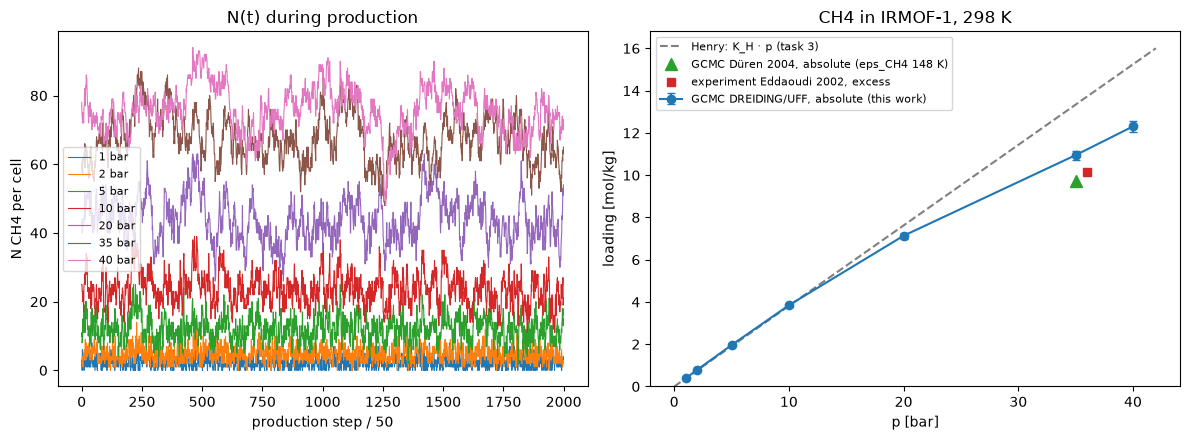

In [6]:
# Literature at 35 bar (see markdown below)
duren_sim_mol_kg = 217.45 / 22414 * 1000          # Düren 2004, Table 1: 217.45 cm3(STP)/g, absolute, GCMC DREIDING
eddaoudi_exp_mol_kg = 135 / 22414 / (rho_fw / 1000) * 1000   # Eddaoudi 2002: 135 cm3(STP)/cm3 at 36 atm, excess
row35 = isotherm[isotherm[:, 0] == 35][0]
print(f"35 bar: GCMC here {row35[4]:.2f} +- {row35[5]:.2f} mol/kg, Düren 2004 (DREIDING, eps_CH4 148 K) {duren_sim_mol_kg:.2f} mol/kg, "
      f"ratio {row35[4] / duren_sim_mol_kg:.3f}; experiment (excess) {eddaoudi_exp_mol_kg:.2f} mol/kg")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
for p_bar, trace in traces.items():
    ax1.plot(trace[::50], lw=0.8, label=f"{p_bar} bar")
ax1.set_xlabel("production step / 50")
ax1.set_ylabel("N CH4 per cell")
ax1.set_title("N(t) during production")
ax1.legend(fontsize=8)

p_grid = np.linspace(0, 42, 200)
ax2.errorbar(isotherm[:, 0], isotherm[:, 4], yerr=isotherm[:, 5], fmt="o-", capsize=3, label="GCMC DREIDING/UFF, absolute (this work)")
ax2.plot(p_grid, K_H * p_grid * 1e5, "--", color="gray", label="Henry: K_H · p (task 3)")
ax2.plot([35], [duren_sim_mol_kg], "^", color="C2", ms=8, label="GCMC Düren 2004, absolute (eps_CH4 148 K)")
ax2.plot([36], [eddaoudi_exp_mol_kg], "s", color="C3", label="experiment Eddaoudi 2002, excess")
ax2.set_xlabel("p [bar]")
ax2.set_ylabel("loading [mol/kg]")
ax2.set_ylim(0, None)
ax2.set_title("CH4 in IRMOF-1, 298 K")
ax2.legend(fontsize=8)
fig.tight_layout()
fig.savefig("../results/isotherm_uff_298K.png", dpi=150)

## Comparison with the literature

**Düren, Sarkisov, Yaghi, Snurr, *Langmuir* 2004, 20, 2683, Table 1** (GCMC, all-atom DREIDING for the framework, united-atom CH4 with sigma 3.73 A and eps 148 K, cutoff 12.8 A, Lorentz-Berthelot, 298 K):

| quantity, IRMOF-1 | value |
|---|---|
| loading at 35 bar, absolute | 128.29 cm³(STP)/cm³ = 217.45 cm³(STP)/g = **9.70 mol/kg** |
| Q_st at low loading | 10.6 kJ/mol |
| V_free | 81% |
| rho_crys | 0.59 g/cm³ |

Experiment (Eddaoudi et al., *Science* 2002, 295, 469): ≈ 135 cm³(STP)/cm³ at 36 atm, **excess**, ≈ 10.2 mol/kg. Düren reports a mean deviation simulation/experiment of 5.7% (DREIDING) and 7.4% (UFF) over the whole isotherm.

**How our isotherm compares** (number printed above):

- At 1 bar GCMC coincides with the Henry line from task 3 within 2%. That is the consistency check between task 3 and task 4.
- At 35 bar we are about 13% above Düren. The main cause is the CH4 model: we use eps = 158.5 K (Martin et al. 2001, via Dubbeldam 2007), Düren 148 K. A 7% deeper well enters exponentially in exp(−U/T) and hence in the loading. Also: Zn via UFF instead of DREIDING, cutoff 12 A with shift instead of 12.8 A without shift.
- Experiment measures excess, we compute absolute. Excess = absolute − V_pore·rho_bulk. With V_free 0.81 and bulk CH4 at 36 bar ≈ 1.5 mol/L the correction is ≈ 2.1 mol/kg, so our absolute number lands close to the experiment after correction.
- No published K_H for CH4 in IRMOF-1 with exactly this force field was found; Q_st 10.6 kJ/mol (Düren) is the nearest low-loading reference. The comparison therefore goes through the isotherm.

**Limitations**: united-atom CH4, rigid framework, no electrostatics, no tail correction. At 40 bar the insertion acceptance drops to 13%, and 100,000 production steps give a 2% standard error there; for a publication-quality isotherm you want 10× more steps (Düren: 500,000 + 500,000).